# Carbon-Aware AI: Measuring and Reducing the Footprint of Model Training
**AI459 – AI for Sustainability, SVNIT Surat (B.Tech AI, Sem VIII)**
**Author:** Lakshit Vedant (U23AI015) – individual project

This notebook trains a CIFAR-10 CNN in **five variants** and measures **energy (kWh)** and **CO₂ (kg)** with CodeCarbon:

| # | Variant | Idea |
|---|---------|------|
| 1 | `baseline_fp32` | normal FP32 training |
| 2 | `mixed_precision` | AMP training (fp16 on GPU) |
| 3 | `pruned` | baseline → 50 % global L1 pruning → fine-tune |
| 4 | `quantized` | baseline → post-training dynamic INT8 |
| 5 | `pruned_quantized` | pruned model → INT8 |




## 1. Setup

In [1]:
!pip -q install codecarbon

In [2]:
import os, io, time, copy, math, json, shutil, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torch.nn.utils.prune as prune
import torchvision
import matplotlib.pyplot as plt
from contextlib import nullcontext
from codecarbon import OfflineEmissionsTracker
warnings.filterwarnings("ignore")

FORCE_QUICK = False          # set True for a ~3 min smoke test
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only"
QUICK = FORCE_QUICK or DEVICE.type == "cpu"

CFG = dict(epochs=15, ft_epochs=4, bs=256, n_train=50000, n_test=10000,
           prune_amount=0.5, bench_images=2000, bench_repeats=3, seed=0, country="IND")
if QUICK:
    CFG.update(epochs=3, ft_epochs=1, n_train=10000, n_test=2000, bench_images=500, bench_repeats=2)

torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
torch.backends.cudnn.benchmark = True
os.makedirs("results/codecarbon", exist_ok=True); os.makedirs("report_assets", exist_ok=True)
print(f"Device: {DEVICE} ({GPU_NAME}) | QUICK={QUICK}\n{CFG}")
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Use Runtime > Change runtime type > T4 GPU for the full experiment.")

Device: cuda (Tesla T4) | QUICK=False
{'epochs': 15, 'ft_epochs': 4, 'bs': 256, 'n_train': 50000, 'n_test': 10000, 'prune_amount': 0.5, 'bench_images': 2000, 'bench_repeats': 3, 'seed': 0, 'country': 'IND'}


## 2. Dataset – CIFAR-10 (`cifar-10-batches-py`)
`torchvision` downloads the official *CIFAR-10 python version* and extracts it to `data/cifar-10-batches-py/`.
If you already have that folder, upload it to `/content/data/` and it will be used instead of downloading.
The whole dataset is kept on the GPU and augmented there (random crop + flip), so training measures compute, not data-loader overhead.

In [3]:
import os, shutil
from google.colab import drive
drive.mount("/content/drive")

SRC = "/content/drive/MyDrive/data/cifar-10-batches-py"   # change if you put it elsewhere
DST = "/content/data/cifar-10-batches-py"

os.makedirs("/content/data", exist_ok=True)
if not os.path.exists(DST):
    shutil.copytree(SRC, DST)
print(sorted(os.listdir(DST)))

Mounted at /content/drive
['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


In [4]:
root = "data"
tr = torchvision.datasets.CIFAR10(root, train=True, download=False)
te = torchvision.datasets.CIFAR10(root, train=False, download=False)
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)

def to_tensor(ds):
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.0
    return (x - MEAN) / STD, torch.tensor(ds.targets)

g = torch.Generator().manual_seed(CFG["seed"])
Xtr, Ytr = to_tensor(tr); Xte, Yte = to_tensor(te)
i_tr = torch.randperm(len(Xtr), generator=g)[:CFG["n_train"]]
i_te = torch.randperm(len(Xte), generator=g)[:CFG["n_test"]]
Xtr, Ytr = Xtr[i_tr].to(DEVICE), Ytr[i_tr].to(DEVICE)
Xte, Yte = Xte[i_te].to(DEVICE), Yte[i_te].to(DEVICE)
Xte_cpu = Xte.cpu()
print("train:", tuple(Xtr.shape), "| test:", tuple(Xte.shape))

AR32 = None
def augment(x):
    B = x.size(0); d = x.device
    flip = torch.rand(B, device=d) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (B,), device=d); j = torch.randint(0, 9, (B,), device=d)
    ar = torch.arange(32, device=d)
    ih = (i[:, None] + ar)[:, None, :, None]; iw = (j[:, None] + ar)[:, None, None, :]
    return xp[torch.arange(B, device=d)[:, None, None, None], torch.arange(3, device=d)[None, :, None, None], ih, iw]

def batches(X, Y, bs, shuffle=False, aug=False):
    order = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for k in range(0, len(X), bs):
        j = order[k:k + bs]; x = X[j]
        yield (augment(x) if aug else x), Y[j]

train: (50000, 3, 32, 32) | test: (10000, 3, 32, 32)


## 3. Model, energy meter, training and evaluation

In [5]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class CarbonNet(nn.Module):
    """VGG-style CNN (6 conv + 2 Linear). The large Linear layer makes dynamic INT8 quantization meaningful."""
    def __init__(self, nc=10):
        super().__init__()
        self.features = nn.Sequential(
            block(3, 64), block(64, 64), nn.MaxPool2d(2),
            block(64, 128), block(128, 128), nn.MaxPool2d(2),
            block(128, 256), block(256, 256), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256 * 16, 1024), nn.ReLU(inplace=True),
                                        nn.Dropout(0.4), nn.Linear(1024, nc))
    def forward(self, x):
        return self.classifier(self.features(x))

print("parameters:", sum(p.numel() for p in CarbonNet().parameters()))

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

class Meter:
    """Context manager around CodeCarbon's OfflineEmissionsTracker."""
    def __init__(self, name):
        self.tracker = OfflineEmissionsTracker(project_name=name, output_dir="results/codecarbon",
            country_iso_code=CFG["country"], measure_power_secs=1, log_level="error",
            save_to_file=True, allow_multiple_runs=True)
    def __enter__(self):
        sync(); self.t0 = time.time(); self.tracker.start(); return self
    def __exit__(self, *exc):
        sync(); co2 = self.tracker.stop(); self.seconds = time.time() - self.t0
        d = getattr(self.tracker, "final_emissions_data", None)
        self.kwh = float(d.energy_consumed) if d is not None else 0.0
        self.co2 = float(co2) if co2 is not None else 0.0
        self.cpu_kwh = float(getattr(d, "cpu_energy", 0) or 0); self.gpu_kwh = float(getattr(d, "gpu_energy", 0) or 0)
        self.ram_kwh = float(getattr(d, "ram_energy", 0) or 0)

def amp_ctx(device, amp):
    if not amp: return nullcontext()
    return torch.autocast(device_type=device.type, dtype=torch.float16 if device.type == "cuda" else torch.bfloat16)

def train(model, X, Y, epochs, amp=False, max_lr=0.1, tag=""):
    model.to(DEVICE).train()
    steps = math.ceil(len(X) / CFG["bs"])
    opt = torch.optim.SGD(model.parameters(), lr=max_lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, total_steps=epochs * steps, pct_start=0.25)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp and DEVICE.type == "cuda"))
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
    for ep in range(epochs):
        model.train(); tot = torch.zeros((), device=DEVICE); n = 0
        for x, y in batches(X, Y, CFG["bs"], shuffle=True, aug=True):
            opt.zero_grad(set_to_none=True)
            with amp_ctx(DEVICE, amp):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.detach() * len(y); n += len(y)
        print(f"  [{tag}] epoch {ep + 1}/{epochs}  loss {tot.item() / n:.4f}")

@torch.no_grad()
def evaluate(model, X, Y, device, amp=False, bs=500):
    model.to(device).eval(); correct = 0
    for k in range(0, len(X), bs):
        x, y = X[k:k + bs].to(device), Y[k:k + bs].to(device)
        with amp_ctx(device, amp):
            correct += (model(x).argmax(1) == y).sum().item()
    return 100.0 * correct / len(X)

@torch.no_grad()
def bench_inference(model, amp=False):
    """Inference energy on CPU (needed for INT8 models; keeps the comparison fair)."""
    cpu = torch.device("cpu"); m = copy.deepcopy(model).to(cpu).eval()
    X = Xte_cpu[:CFG["bench_images"]]; R = CFG["bench_repeats"]; n = len(X) * R
    with amp_ctx(cpu, amp): m(X[:64])                      # warm-up
    with Meter("inference") as mt:
        t0 = time.perf_counter()
        for _ in range(R):
            for k in range(0, len(X), 100):
                with amp_ctx(cpu, amp): m(X[k:k + 100])
        dt = time.perf_counter() - t0
    return mt.kwh / n * 1000, mt.co2 / n * 1000, dt / n * 1000   # kWh/1k img, kg/1k img, ms/img

def warmup_gpu(steps=6):
    """Untracked warm-up (CUDA context, cuDNN autotune, AMP kernels) so the first tracked run is not penalised."""
    if DEVICE.type != "cuda": return
    m = CarbonNet().to(DEVICE).train(); opt = torch.optim.SGD(m.parameters(), lr=0.01)
    x, y = Xtr[:CFG["bs"]], Ytr[:CFG["bs"]]
    for amp in (False, True):
        for _ in range(steps):
            opt.zero_grad(set_to_none=True)
            with amp_ctx(DEVICE, amp): loss = F.cross_entropy(m(x), y)
            loss.backward(); opt.step()
    sync(); del m, opt; torch.cuda.empty_cache()


parameters: 5351882


## 4. Compression helpers (pruning, INT8 quantization, model size)

In [6]:
def prunable(model):
    return [(m, "weight") for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]

def prune_global(model, amount):
    prune.global_unstructured(prunable(model), pruning_method=prune.L1Unstructured, amount=amount)

def prune_make_permanent(model):
    for m, name in prunable(model): prune.remove(m, name)

def sparsity_and_nonzero(model):
    tot = nz = 0
    for m, _ in prunable(model):
        tot += m.weight.numel(); nz += (m.weight != 0).sum().item()
    return 100.0 * (1 - nz / tot), nz

def quantize_int8(model):
    return torch.ao.quantization.quantize_dynamic(copy.deepcopy(model).cpu().eval(), {nn.Linear}, dtype=torch.qint8)

def size_mb(model):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf); return buf.tell() / 1e6

## 5. Run the five experiments
Energy of *pruned* / *quantized* / *pruned+INT8* **includes the baseline training they depend on** (honest accounting);
the column `train_kwh_incremental` shows only the extra energy of that step.

In [7]:
rows = []
PRETTY = {"baseline_fp32": "Baseline FP32", "mixed_precision": "Mixed precision (AMP)",
          "pruned": f"Pruned {int(CFG['prune_amount']*100)}% + FT", "quantized": "INT8 quantized",
          "pruned_quantized": "Pruned + INT8"}

def add_row(name, model, total, inc, amp_infer=False, sparsity=0.0, nonzero=None, note=""):
    cpu_model = name in ("quantized", "pruned_quantized")
    acc = evaluate(model, Xte, Yte, torch.device("cpu") if cpu_model else DEVICE, amp=amp_infer)
    ikwh, ico2, lat = bench_inference(model, amp=False)   # CPU FP32/INT8 for every variant = like-for-like comparison
    n_params = nonzero if nonzero is not None else sum(p.numel() for p in model.parameters())
    rows.append(dict(variant=name, accuracy_pct=round(acc, 2),
        train_kwh=total["kwh"], train_co2_kg=total["co2"], train_time_s=round(total["sec"], 1),
        train_kwh_incremental=inc["kwh"], infer_kwh_per_1k=ikwh, infer_co2_g_per_1k=ico2 * 1000,
        latency_ms_per_img=round(lat, 3), model_size_mb=round(size_mb(model), 2),
        sparsity_pct=round(sparsity, 1), nonzero_params=n_params, note=note))
    print(f"  -> {name}: acc {acc:.2f}% | train {total['kwh']*1000:.3f} Wh | {total['co2']*1000:.3f} g CO2 | infer {lat:.3f} ms/img")
    pd.DataFrame(rows).to_csv("results/results.csv", index=False)

def pack(m): return dict(kwh=m.kwh, co2=m.co2, sec=m.seconds)
def plus(a, b): return {k: a[k] + b[k] for k in a}

warmup_gpu()   # untracked warm-up so the baseline is not penalised

# 1) baseline FP32
print("[1/5] Baseline FP32")
base = CarbonNet()
with Meter("baseline_fp32") as m_base:
    train(base, Xtr, Ytr, CFG["epochs"], amp=False, tag="fp32")
B = pack(m_base)
BASE_BREAKDOWN = dict(cpu=m_base.cpu_kwh, gpu=m_base.gpu_kwh, ram=m_base.ram_kwh)
add_row("baseline_fp32", base, B, B)

# 2) mixed precision (from scratch)
print("[2/5] Mixed precision (AMP)")
mp = CarbonNet()
with Meter("mixed_precision") as m_mp:
    train(mp, Xtr, Ytr, CFG["epochs"], amp=True, tag="amp")
M = pack(m_mp)
add_row("mixed_precision", mp, M, M, amp_infer=True, note="AMP training; accuracy checked with fp16 autocast")

# 3) global L1 pruning + fine-tune
print("[3/5] Global L1 pruning + fine-tune")
pr = copy.deepcopy(base).to(DEVICE)
prune_global(pr, CFG["prune_amount"])
with Meter("prune_finetune") as m_ft:
    train(pr, Xtr, Ytr, CFG["ft_epochs"], max_lr=0.01, tag="finetune")
prune_make_permanent(pr)
sp, nz = sparsity_and_nonzero(pr); F_ = pack(m_ft)
add_row("pruned", pr, plus(B, F_), F_, sparsity=sp, nonzero=nz, note="unstructured sparsity (dense speed unchanged)")

# 4) dynamic INT8 quantization of the baseline (no training)
print("[4/5] Dynamic INT8 quantization")
q = quantize_int8(base)
add_row("quantized", q, B, dict(kwh=0.0, co2=0.0, sec=0.0), nonzero=sum(p.numel() for p in base.parameters()), note="INT8 on Linear layers")

# 5) pruned + INT8
print("[5/5] Pruned + INT8")
pq = quantize_int8(pr)
add_row("pruned_quantized", pq, plus(B, F_), F_, sparsity=sp, nonzero=nz, note="pruning then INT8")

df = pd.DataFrame(rows)
df["train_wh"] = df.train_kwh * 1000; df["train_co2_g"] = df.train_co2_kg * 1000
df["infer_mwh_per_1k"] = df.infer_kwh_per_1k * 1e6
print("\nDone.")

[codecarbon INFO @ 18:26:32] offline tracker init
[codecarbon WARNING @ 18:26:32] Multiple instances of codecarbon are allowed to run at the same time.


[1/5] Baseline FP32
  [fp32] epoch 1/15  loss 1.5933
  [fp32] epoch 2/15  loss 1.2879
  [fp32] epoch 3/15  loss 1.2186
  [fp32] epoch 4/15  loss 1.1291
  [fp32] epoch 5/15  loss 1.0371
  [fp32] epoch 6/15  loss 0.9708
  [fp32] epoch 7/15  loss 0.9161
  [fp32] epoch 8/15  loss 0.8753
  [fp32] epoch 9/15  loss 0.8390
  [fp32] epoch 10/15  loss 0.8057
  [fp32] epoch 11/15  loss 0.7746
  [fp32] epoch 12/15  loss 0.7433
  [fp32] epoch 13/15  loss 0.7145
  [fp32] epoch 14/15  loss 0.6867
  [fp32] epoch 15/15  loss 0.6721
  -> baseline_fp32: acc 91.32% | train 3.413 Wh | 2.435 g CO2 | infer 4.716 ms/img
[2/5] Mixed precision (AMP)
  [amp] epoch 1/15  loss 1.6049
  [amp] epoch 2/15  loss 1.3009
  [amp] epoch 3/15  loss 1.2203
  [amp] epoch 4/15  loss 1.1276
  [amp] epoch 5/15  loss 1.0337
  [amp] epoch 6/15  loss 0.9675
  [amp] epoch 7/15  loss 0.9155
  [amp] epoch 8/15  loss 0.8734
  [amp] epoch 9/15  loss 0.8399
  [amp] epoch 10/15  loss 0.8067
  [amp] epoch 11/15  loss 0.7778
  [amp] epoch 

## 6. Results table

In [8]:
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
show = df[["variant", "accuracy_pct", "train_wh", "train_co2_g", "train_time_s", "infer_mwh_per_1k",
           "latency_ms_per_img", "model_size_mb", "sparsity_pct"]].copy()
show["variant"] = show["variant"].map(PRETTY)
display(show.round(3))

b = df.iloc[0]
print(f"\nCodeCarbon implied grid factor: {b.train_co2_kg / b.train_kwh:.3f} kg/kWh (India)")
print(f"Baseline energy split (kWh): CPU {BASE_BREAKDOWN['cpu']:.5f} | GPU {BASE_BREAKDOWN['gpu']:.5f} | RAM {BASE_BREAKDOWN['ram']:.5f}")
for _, r in df.iloc[1:].iterrows():
    print(f"{PRETTY[r.variant]:<24} acc {r.accuracy_pct - b.accuracy_pct:+.2f} pts | train energy {100*(r.train_kwh/b.train_kwh-1):+.1f}% | "
          f"infer energy {100*(r.infer_kwh_per_1k/b.infer_kwh_per_1k-1):+.1f}% | size {b.model_size_mb/r.model_size_mb:.2f}x smaller")

,variant,accuracy_pct,train_wh,train_co2_g,train_time_s,infer_mwh_per_1k,latency_ms_per_img,model_size_mb,sparsity_pct
0,Baseline FP32,91.32,3.413,2.435,153.6,60.535,4.716,21.43,0.0
1,Mixed precision (AMP),91.45,1.952,1.393,88.3,59.969,4.636,21.43,0.0
2,Pruned 50% + FT,91.51,4.382,3.126,197.3,59.815,4.657,21.43,50.0
3,INT8 quantized,91.32,3.413,2.435,153.6,55.991,4.579,8.82,0.0
4,Pruned + INT8,91.45,4.382,3.126,197.3,52.585,4.455,8.82,50.0



CodeCarbon implied grid factor: 0.713 kg/kWh (India)
Baseline energy split (kWh): CPU 0.00015 | GPU 0.00284 | RAM 0.00042
Mixed precision (AMP)    acc +0.13 pts | train energy -42.8% | infer energy -0.9% | size 1.00x smaller
Pruned 50% + FT          acc +0.19 pts | train energy +28.4% | infer energy -1.2% | size 1.00x smaller
INT8 quantized           acc +0.00 pts | train energy +0.0% | infer energy -7.5% | size 2.43x smaller
Pruned + INT8            acc +0.13 pts | train energy +28.4% | infer energy -13.1% | size 2.43x smaller


## 7. Charts

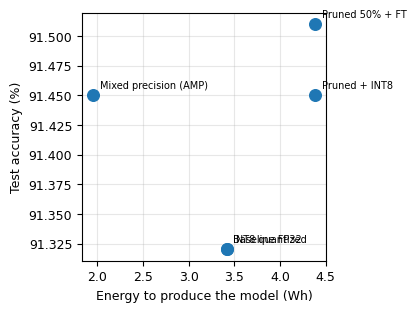

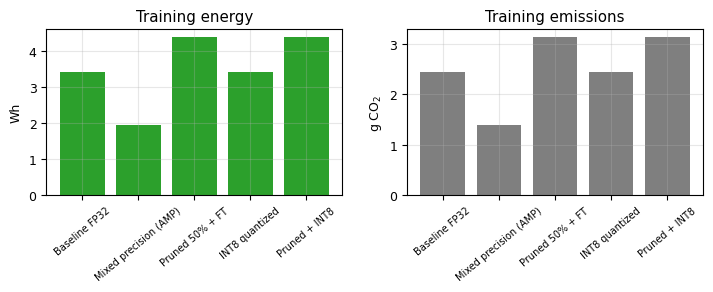

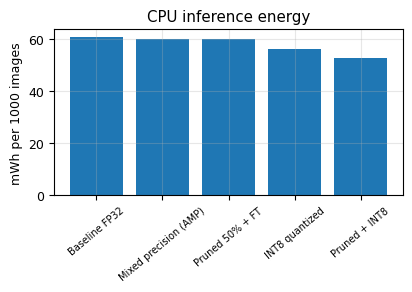

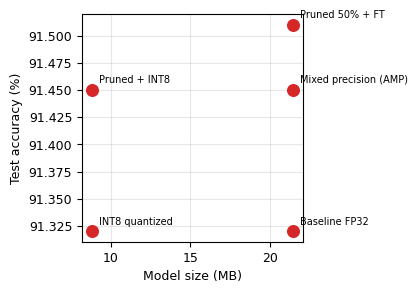

In [9]:
names = [PRETTY[v] for v in df.variant]
plt.rcParams.update({"font.size": 9, "axes.grid": True, "grid.alpha": 0.3})

# 1) accuracy vs energy
fig, ax = plt.subplots(figsize=(4.2, 3.2))
ax.scatter(df.train_wh, df.accuracy_pct, s=70, c="tab:blue", zorder=3)
for x, y, n in zip(df.train_wh, df.accuracy_pct, names):
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=7)
ax.set_xlabel("Energy to produce the model (Wh)"); ax.set_ylabel("Test accuracy (%)")
fig.tight_layout(); fig.savefig("report_assets/accuracy_vs_energy.png", dpi=300); plt.show()

# 2) training energy and CO2
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
axs[0].bar(names, df.train_wh, color="tab:green"); axs[0].set_ylabel("Wh"); axs[0].set_title("Training energy")
axs[1].bar(names, df.train_co2_g, color="tab:gray"); axs[1].set_ylabel("g CO$_2$"); axs[1].set_title("Training emissions")
for a in axs: a.tick_params(axis="x", rotation=40, labelsize=7)
fig.tight_layout(); fig.savefig("report_assets/energy_co2_bars.png", dpi=300); plt.show()

# 3) inference energy
fig, ax = plt.subplots(figsize=(4.2, 3.0))
ax.bar(names, df.infer_mwh_per_1k, color="tab:blue")
ax.set_ylabel("mWh per 1000 images"); ax.set_title("CPU inference energy"); ax.tick_params(axis="x", rotation=40, labelsize=7)
fig.tight_layout(); fig.savefig("report_assets/inference_energy.png", dpi=300); plt.show()

# 4) model size vs accuracy
fig, ax = plt.subplots(figsize=(4.2, 3.0))
ax.scatter(df.model_size_mb, df.accuracy_pct, s=70, c="tab:red", zorder=3)
for x, y, n in zip(df.model_size_mb, df.accuracy_pct, names):
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=7)
ax.set_xlabel("Model size (MB)"); ax.set_ylabel("Test accuracy (%)")
fig.tight_layout(); fig.savefig("report_assets/size_vs_accuracy.png", dpi=300); plt.show()

In [10]:
import os, shutil, pandas as pd
from google.colab import files

os.makedirs("data/csv", exist_ok=True)
print("Select the Electricity Maps CSV (IN-WE hourly)...")
up = files.upload()

for name in up:
    shutil.move(name, f"data/csv/{name}")
REAL_CSV = f"data/csv/{list(up)[0]}"

# quick sanity check
raw = pd.read_csv(REAL_CSV)
print("Saved to:", REAL_CSV, "| rows:", len(raw))
print("Columns:", list(raw.columns))
display(raw.head(3))

Select the Electricity Maps CSV (IN-WE hourly)...


IndexError: list index out of range

## 8. Carbon-aware scheduler
Picks the start time that minimises `emissions = energy × mean grid carbon intensity` over the job window, subject to a deadline.

> **Data:** by default a **synthetic** solar-heavy Indian-grid profile is used (clearly labelled in the report).
> For final results download real hourly data for **IN-WE (Western India – covers Gujarat)** from the
> [Electricity Maps data portal](https://portal.electricitymaps.com/datasets) (free), upload the CSV to Colab
> (left sidebar → Files) and set `REAL_CSV = "your_file.csv"` below.

carbon-intensity data: synthetic | 336 hours | mean 658 gCO2/kWh
Run now  (2026-11-03 23:00:00): 742 gCO2/kWh -> 2.534 kg CO2
Best     (2026-11-04 17:00:00): 513 gCO2/kWh -> 1.750 kg CO2
Saving by waiting: 30.9%
Mean saving over all submission times: 20.2% | max 32.8%


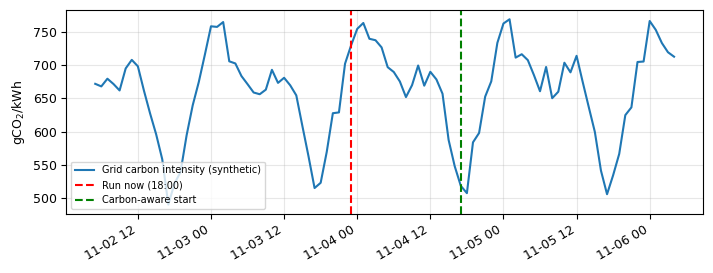

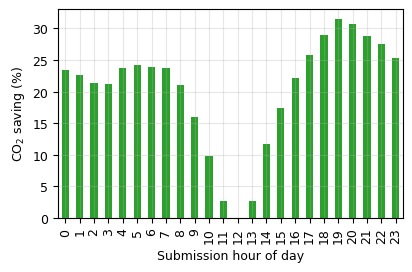

In [11]:
REAL_CSV = globals().get("REAL_CSV")
SAMPLE_PATH = "data/grid_carbon_intensity_sample.csv"

def make_sample_intensity(path=SAMPLE_PATH, days=14, seed=0):
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2026-11-02", periods=days * 24, freq="h"); h = idx.hour.values
    ci = 690 - 170 * np.exp(-((h - 12.5) / 3.0) ** 2) + 70 * np.exp(-((h - 20) / 2.0) ** 2) - 20 * (h < 5) + rng.normal(0, 15, len(idx))
    out = pd.DataFrame({"datetime": idx, "carbon_intensity_gco2_per_kwh": np.clip(ci, 150, None).round(1)})
    os.makedirs(os.path.dirname(path), exist_ok=True); out.to_csv(path, index=False); return out

def load_intensity(path):
    raw = pd.read_csv(path)
    tcol = next(c for c in raw.columns if "date" in c.lower() or "time" in c.lower())
    ccols = [c for c in raw.columns if ("carbon" in c.lower() or "intensity" in c.lower())
             and not any(k in c.lower() for k in ("free", "cfe", "renew", "%"))]
    ccol = next((c for c in ccols if "direct" in c.lower()), ccols[0])
    d = pd.DataFrame({"datetime": pd.to_datetime(raw[tcol]) + pd.Timedelta(hours=5.5),"ci": pd.to_numeric(raw[ccol], errors="coerce")})
    return d.dropna().set_index("datetime").resample("1h").mean().interpolate().reset_index()

def schedule(df, energy_kwh, duration_h, deadline_h=24, now_idx=0):
    ci = df["ci"].to_numpy(); d = max(1, math.ceil(duration_h))
    last = min(now_idx + int(deadline_h) - d, len(ci) - d)
    if last < now_idx: raise ValueError("Deadline shorter than job duration (or data too short).")
    avgs = {s: ci[s:s + d].mean() for s in range(now_idx, last + 1)}
    best = min(avgs, key=avgs.get); worst = max(avgs, key=avgs.get); now_avg = avgs[now_idx]
    kg = lambda a: energy_kwh * a / 1000.0
    return dict(run_now_start=df["datetime"].iloc[now_idx], best_start=df["datetime"].iloc[best], best_idx=best,
                worst_start=df["datetime"].iloc[worst], ci_run_now=now_avg, ci_best=avgs[best], ci_worst=avgs[worst],
                co2_run_now_kg=kg(now_avg), co2_best_kg=kg(avgs[best]), co2_worst_kg=kg(avgs[worst]),
                saving_pct=100 * (now_avg - avgs[best]) / now_avg)

if REAL_CSV:
    ci_df = load_intensity(REAL_CSV); DATA_SRC = "real (Electricity Maps)"
else:
    make_sample_intensity(); ci_df = load_intensity(SAMPLE_PATH); DATA_SRC = "synthetic"
print("carbon-intensity data:", DATA_SRC, "|", len(ci_df), "hours | mean", round(ci_df.ci.mean()), "gCO2/kWh")

CAMPAIGN_RUNS, JOB_HOURS, DEADLINE_H = 1000, 2, 24      # mimic a large training campaign
job_kwh = df.loc[df.variant == "baseline_fp32", "train_kwh"].iloc[0] * CAMPAIGN_RUNS

# example: job submitted at 18:00 of day 2, 24 h deadline
NOW = 24 + 18
s = schedule(ci_df, job_kwh, JOB_HOURS, DEADLINE_H, NOW)
print(f"Run now  ({s['run_now_start']}): {s['ci_run_now']:.0f} gCO2/kWh -> {s['co2_run_now_kg']:.3f} kg CO2")
print(f"Best     ({s['best_start']}): {s['ci_best']:.0f} gCO2/kWh -> {s['co2_best_kg']:.3f} kg CO2")
print(f"Saving by waiting: {s['saving_pct']:.1f}%")

# average over every possible submission hour (days 2-6)
sweep = pd.DataFrame([dict(hour=i % 24, saving=schedule(ci_df, job_kwh, JOB_HOURS, DEADLINE_H, i)["saving_pct"]) for i in range(24, 24 * 6)])
print(f"Mean saving over all submission times: {sweep.saving.mean():.1f}% | max {sweep.saving.max():.1f}%")

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.plot(ci_df["datetime"][:96], ci_df["ci"][:96], label=f"Grid carbon intensity ({DATA_SRC})")
ax.axvline(s["run_now_start"], color="red", ls="--", label="Run now (18:00)")
ax.axvline(s["best_start"], color="green", ls="--", label="Carbon-aware start")
ax.set_ylabel("gCO$_2$/kWh"); ax.legend(fontsize=7); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig("report_assets/scheduler.png", dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(4.2, 2.8))
sweep.groupby("hour").saving.mean().plot.bar(ax=ax, color="tab:green")
ax.set_xlabel("Submission hour of day"); ax.set_ylabel("CO$_2$ saving (%)")
fig.tight_layout(); fig.savefig("report_assets/scheduler_by_hour.png", dpi=300); plt.show()

## 9. Export everything for the report
Writes `report_assets/results_table.tex`, `report_assets/numbers.tex` (macros used by the LaTeX report), the CSVs, and zips it all for download.
Put the downloaded `report_assets/` folder next to `report.tex` (same folder) on Overleaf and compile.

In [12]:
TEX = {"baseline_fp32": "Baseline FP32", "mixed_precision": "Mixed precision (AMP)",
       "pruned": f"Pruned {int(CFG['prune_amount']*100)}\\% + FT", "quantized": "INT8 quantized", "pruned_quantized": "Pruned + INT8"}
L = [r"\begin{tabular}{lccccccc}", r"\hline",
     r"Variant & Acc. (\%) & Train E (Wh) & Train CO$_2$ (g) & Infer. E (mWh/1k) & Latency (ms/img) & Size (MB) & Sparsity (\%) \\", r"\hline"]
for r in df.itertuples():
    L.append(f"{TEX[r.variant]} & {r.accuracy_pct:.2f} & {r.train_wh:.2f} & {r.train_co2_g:.3f} & {r.infer_mwh_per_1k:.3f} & {r.latency_ms_per_img:.3f} & {r.model_size_mb:.2f} & {r.sparsity_pct:.1f} \\\\")
L += [r"\hline", r"\end{tabular}"]
open("report_assets/results_table.tex", "w").write("\n".join(L) + "\n")

R = {v: df[df.variant == v].iloc[0] for v in df.variant}
b, a, p, q_, pq_ = R["baseline_fp32"], R["mixed_precision"], R["pruned"], R["quantized"], R["pruned_quantized"]
pct = lambda x, y: 100 * (x / y - 1)
M = {
 "GpuName": GPU_NAME.replace("_", " "), "NTrain": CFG["n_train"], "NTest": CFG["n_test"], "Epochs": CFG["epochs"], "FTEpochs": CFG["ft_epochs"],
 "PruneAmt": int(CFG["prune_amount"] * 100), "BenchImgs": CFG["bench_images"], "BenchReps": CFG["bench_repeats"],
 "BaseAcc": f"{b.accuracy_pct:.2f}", "BaseWh": f"{b.train_wh:.2f}", "BaseCO": f"{b.train_co2_g:.3f}", "BaseSec": f"{b.train_time_s:.0f}",
 "GridCI": f"{b.train_co2_kg / b.train_kwh * 1000:.0f}", "BaseParams": f"{sum(p_.numel() for p_ in CarbonNet().parameters())/1e6:.2f}",
 "SplitCPU": f"{100*BASE_BREAKDOWN['cpu']/max(b.train_kwh,1e-12):.0f}", "SplitGPU": f"{100*BASE_BREAKDOWN['gpu']/max(b.train_kwh,1e-12):.0f}", "SplitRAM": f"{100*BASE_BREAKDOWN['ram']/max(b.train_kwh,1e-12):.0f}",
 "AmpAcc": f"{a.accuracy_pct:.2f}", "AmpDelta": f"{pct(a.train_kwh, b.train_kwh):+.1f}", "AmpAccDelta": f"{a.accuracy_pct - b.accuracy_pct:+.2f}",
 "PrAcc": f"{p.accuracy_pct:.2f}", "PrAccDelta": f"{p.accuracy_pct - b.accuracy_pct:+.2f}", "PrDelta": f"{pct(p.train_kwh, b.train_kwh):+.1f}", "Sparsity": f"{p.sparsity_pct:.1f}",
 "PrInferDelta": f"{pct(p.infer_kwh_per_1k, b.infer_kwh_per_1k):+.1f}",
 "QAcc": f"{q_.accuracy_pct:.2f}", "QAccDelta": f"{q_.accuracy_pct - b.accuracy_pct:+.2f}", "QSizeX": f"{b.model_size_mb / q_.model_size_mb:.2f}",
 "QInferDelta": f"{pct(q_.infer_kwh_per_1k, b.infer_kwh_per_1k):+.1f}", "QLatDelta": f"{pct(q_.latency_ms_per_img, b.latency_ms_per_img):+.1f}",
 "PQAcc": f"{pq_.accuracy_pct:.2f}", "PQAccDelta": f"{pq_.accuracy_pct - b.accuracy_pct:+.2f}", "PQSizeX": f"{b.model_size_mb / pq_.model_size_mb:.2f}",
 "SchedSrc": DATA_SRC, "SchedNow": f"{s['saving_pct']:.1f}", "SchedMean": f"{sweep.saving.mean():.1f}", "SchedMax": f"{sweep.saving.max():.1f}",
 "SchedRuns": CAMPAIGN_RUNS, "SchedKgNow": f"{s['co2_run_now_kg']:.3f}", "SchedKgBest": f"{s['co2_best_kg']:.3f}",
 "SchedBestStart": str(s["best_start"])[11:16],
}
with open("report_assets/numbers.tex", "w") as f:
    for k, v in M.items():
        f.write("\\def\\%s{%s}\n" % (k, str(v).replace("_", "\\_").replace("%", "\\%")))
df.drop(columns=["note"]).to_csv("report_assets/results_all_columns.csv", index=False)
shutil.copy("results/results.csv", "report_assets/results.csv")
print(open("report_assets/numbers.tex").read())

\def\GpuName{Tesla T4}
\def\NTrain{50000}
\def\NTest{10000}
\def\Epochs{15}
\def\FTEpochs{4}
\def\PruneAmt{50}
\def\BenchImgs{2000}
\def\BenchReps{3}
\def\BaseAcc{91.32}
\def\BaseWh{3.41}
\def\BaseCO{2.435}
\def\BaseSec{154}
\def\GridCI{713}
\def\BaseParams{5.35}
\def\SplitCPU{4}
\def\SplitGPU{83}
\def\SplitRAM{12}
\def\AmpAcc{91.45}
\def\AmpDelta{-42.8}
\def\AmpAccDelta{+0.13}
\def\PrAcc{91.51}
\def\PrAccDelta{+0.19}
\def\PrDelta{+28.4}
\def\Sparsity{50.0}
\def\PrInferDelta{-1.2}
\def\QAcc{91.32}
\def\QAccDelta{+0.00}
\def\QSizeX{2.43}
\def\QInferDelta{-7.5}
\def\QLatDelta{-2.9}
\def\PQAcc{91.45}
\def\PQAccDelta{+0.13}
\def\PQSizeX{2.43}
\def\SchedSrc{synthetic}
\def\SchedNow{30.9}
\def\SchedMean{20.2}
\def\SchedMax{32.8}
\def\SchedRuns{1000}
\def\SchedKgNow{2.534}
\def\SchedKgBest{1.750}
\def\SchedBestStart{17:00}



In [13]:
shutil.rmtree("export", ignore_errors=True); os.makedirs("export")
shutil.copytree("report_assets", "export/report_assets"); shutil.copytree("results", "export/results")
shutil.make_archive("carbon_aware_ai_outputs", "zip", "export")
print("Created carbon_aware_ai_outputs.zip")
try:
    from google.colab import files
    files.download("carbon_aware_ai_outputs.zip")
except Exception as e:
    print("(download manually from the Files panel)", e)

Created carbon_aware_ai_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes / limitations (copied into the report)
* Dynamic INT8 quantization only affects `nn.Linear` layers; unstructured pruning does not speed up dense inference.
* Mixed precision saves energy mainly on GPUs with tensor cores.
* CodeCarbon estimates CPU/RAM power (TDP-based) when hardware counters are unavailable (always the case in Colab) – these are **estimates**, not wall-socket measurements.
* The default grid-carbon-intensity series is synthetic; use real Electricity Maps data (`REAL_CSV`) for final numbers.
* Energy of pruned/quantized models includes the baseline training they depend on.
* Inference energy is benchmarked on CPU (FP32 or INT8) for every variant so the comparison is like-for-like; the AMP model is therefore identical to FP32 at inference – its benefit is in *training* energy.
* Pruned model size is the dense storage size (zeros are still stored); only the non-zero count shrinks.
* Single run with one seed: differences of a few tenths of a percent in accuracy are within noise.
